In [1]:
#import some basic classes
import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.util as cutil
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy import stats

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/AtmBlockPy/lib")
import BlockPlots as BP
import BlockTools as BT

In [2]:
%cd /emmy-noether/home/mf671/DATA/ERA5/gr_tracking/
!cdo selmon,6,7,8 ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023.nc
!ls

/emmy-noether/home/mf671/DATA/ERA5/gr_tracking
cdo    selmonth: Processed 123545136 values from 5 variables over 30681 timesteps [4.25s 140MB]
dictionaries
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1990-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_djf_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023_95perc.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023_md500.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023_new.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_

In [3]:
g = 9.80665  
  
#locations
reanalysis = "ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023.nc"
output = "/Users/michelefilippucci/PLOTS/pres_exeter/block_DAV_climatology.png"
label = "jja"

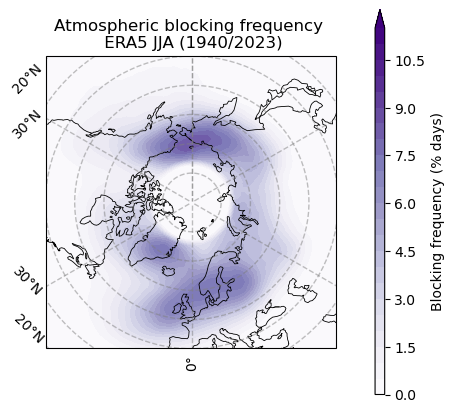

In [4]:
ds = xr.load_dataset(reanalysis)
block_freq = ds["DAV_freq"]
lon = ds['lon'].values
lon = np.append(lon,180)
lat = ds['lat']
block_freq = cutil.add_cyclic_point(block_freq)

fig,ax = plt.subplots(nrows=1,ncols=1,figsize=(5,5),subplot_kw={'projection':ccrs.AzimuthalEquidistant(central_latitude=90)})
extent =[-180,180,40,90]
ax.set_extent(extent, ccrs.PlateCarree())
ax.coastlines(linewidth = 0.6)
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                linewidth=1, 
                color='gray', 
                alpha=0.5, 
                linestyle='--')

gl.top_labels=False
gl.right_labels=False
cont = ax.contourf(lon,lat,block_freq,
                      np.arange(0,12,0.5),
                      extent=[0,90,-180,180],
                      extend = 'max',
                      transform = ccrs.PlateCarree(),
                      cmap = "Purples")
ax.set_title('Atmospheric blocking frequency \n ERA5 JJA (1940/2023)')

cbar = plt.colorbar(cont, orientation='vertical',label="Blocking frequency (% days)",pad=0.1, aspect=40)

plt.show()
#fig.savefig(output,dpi=300)

In [5]:
g = 9.80665  
  
#locations
reanalysis = "ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_jja_1940-2023.nc"
output = "/Users/michelefilippucci/PLOTS/pres_exeter/block_GHA_climatology.png"

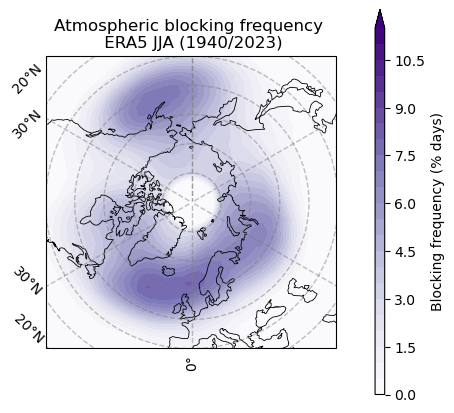

In [6]:
ds = xr.load_dataset(reanalysis)
block_freq = ds["GHA_freq"]
lon = ds['lon'].values
lon = np.append(lon,180)
lat = ds['lat']
block_freq = cutil.add_cyclic_point(block_freq)

fig,ax = plt.subplots(nrows=1,ncols=1,figsize=(5,5),subplot_kw={'projection':ccrs.AzimuthalEquidistant(central_latitude=90)})
extent =[-180,180,40,90]
ax.set_extent(extent, ccrs.PlateCarree())
ax.coastlines(linewidth = 0.6)
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                linewidth=1, 
                color='gray', 
                alpha=0.5, 
                linestyle='--')

gl.top_labels=False
gl.right_labels=False
cont = ax.contourf(lon,lat,block_freq,
                      np.arange(0,12,0.5),
                      extent=[0,90,-180,180],
                      extend = 'max',
                      transform = ccrs.PlateCarree(),
                      cmap = "Purples")
ax.set_title('Atmospheric blocking frequency \n ERA5 JJA (1940/2023)')

cbar = plt.colorbar(cont, orientation='vertical',label="Blocking frequency (% days)",pad=0.1, aspect=40)

plt.show()
#fig.savefig(output,dpi=300)